# New Sensitivity Analysis

All 56 required CSV files found.

Baseline MAE = 136.64 g C/m²
     Observed  Baseline
AF        470    505.60
LOU       200    307.01
JIN       190    149.59
DOU       690    385.55
BC        260    377.48
PGL       430    149.12
ZAN       440    252.28
POI      -161   -180.56

Delta SOC Summary (g C/m²)
     Observed  Baseline  TI_Lower  TI_Higher  NPP_Lower  NPP_Higher  Soil_Lower  Soil_Higher
AF        470    505.60    507.59     523.35     526.75      435.43      528.47       560.36
LOU       200    307.01    289.33     269.59     296.39      226.32      258.48       338.79
JIN       190    149.59    126.60     131.41     137.71      107.38      124.22       161.58
DOU       690    385.55    386.10     405.23     438.70      363.47      311.28       336.73
BC        260    377.48    372.64     395.33     376.68      365.59      389.65       384.68
PGL       430    149.12    154.52     170.83     224.90       61.50      153.64       175.13
ZAN       440    252.28    266.76     274.

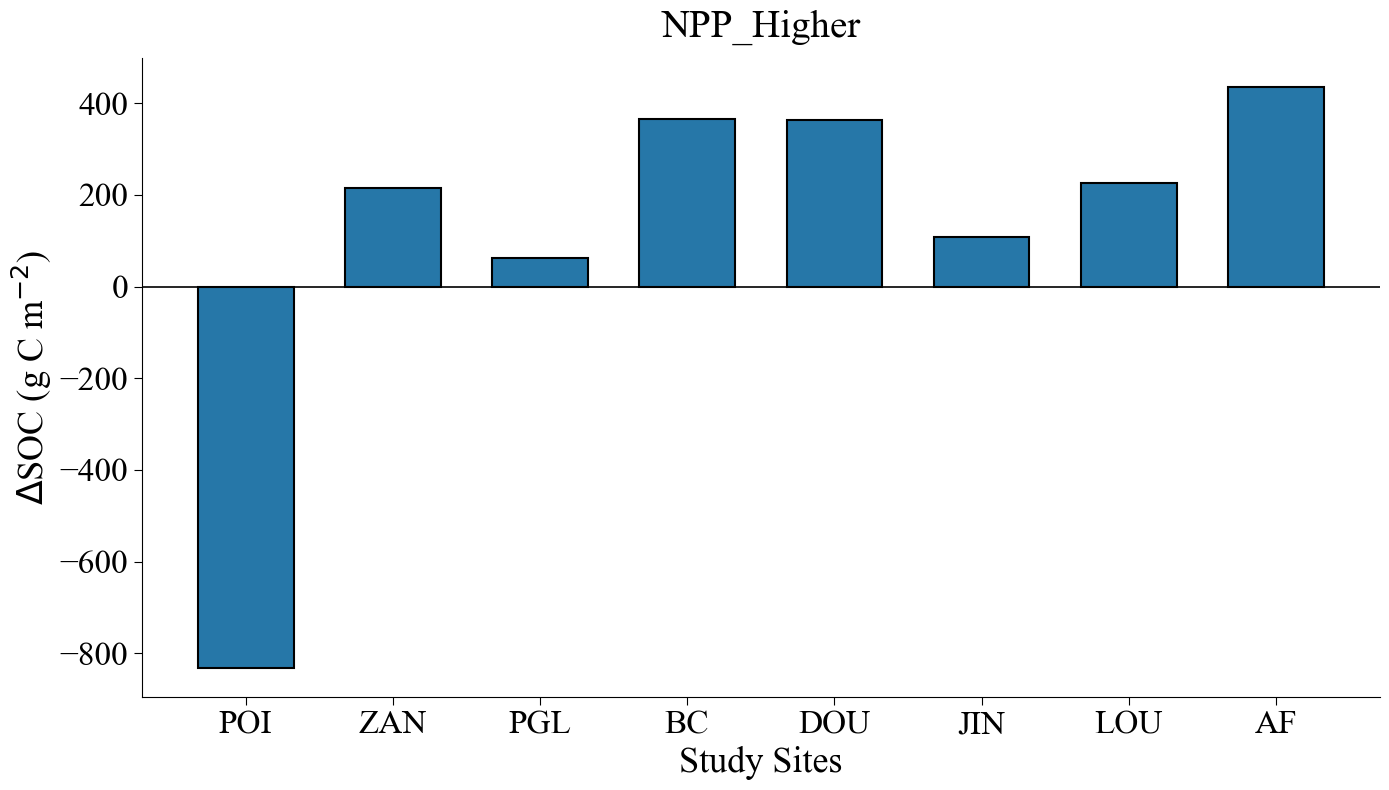

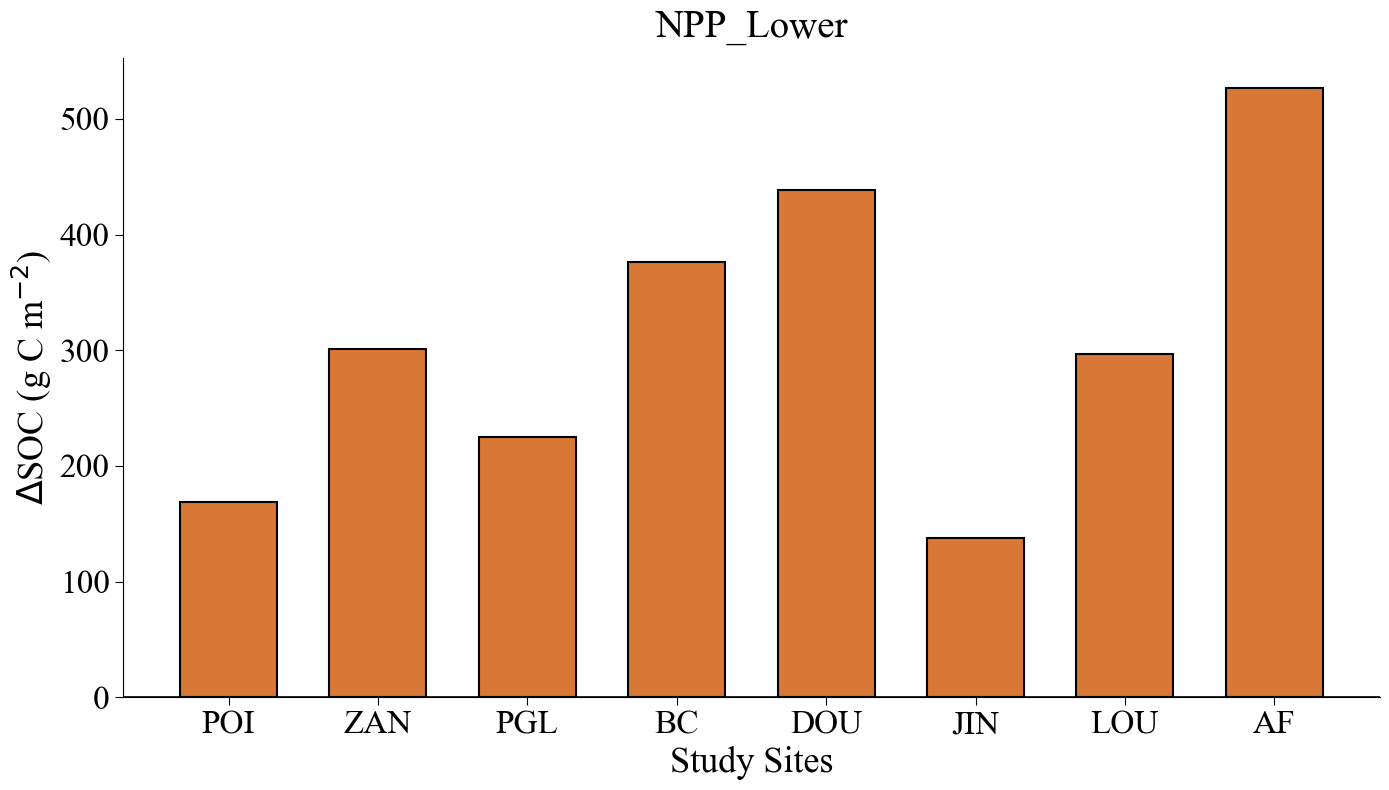

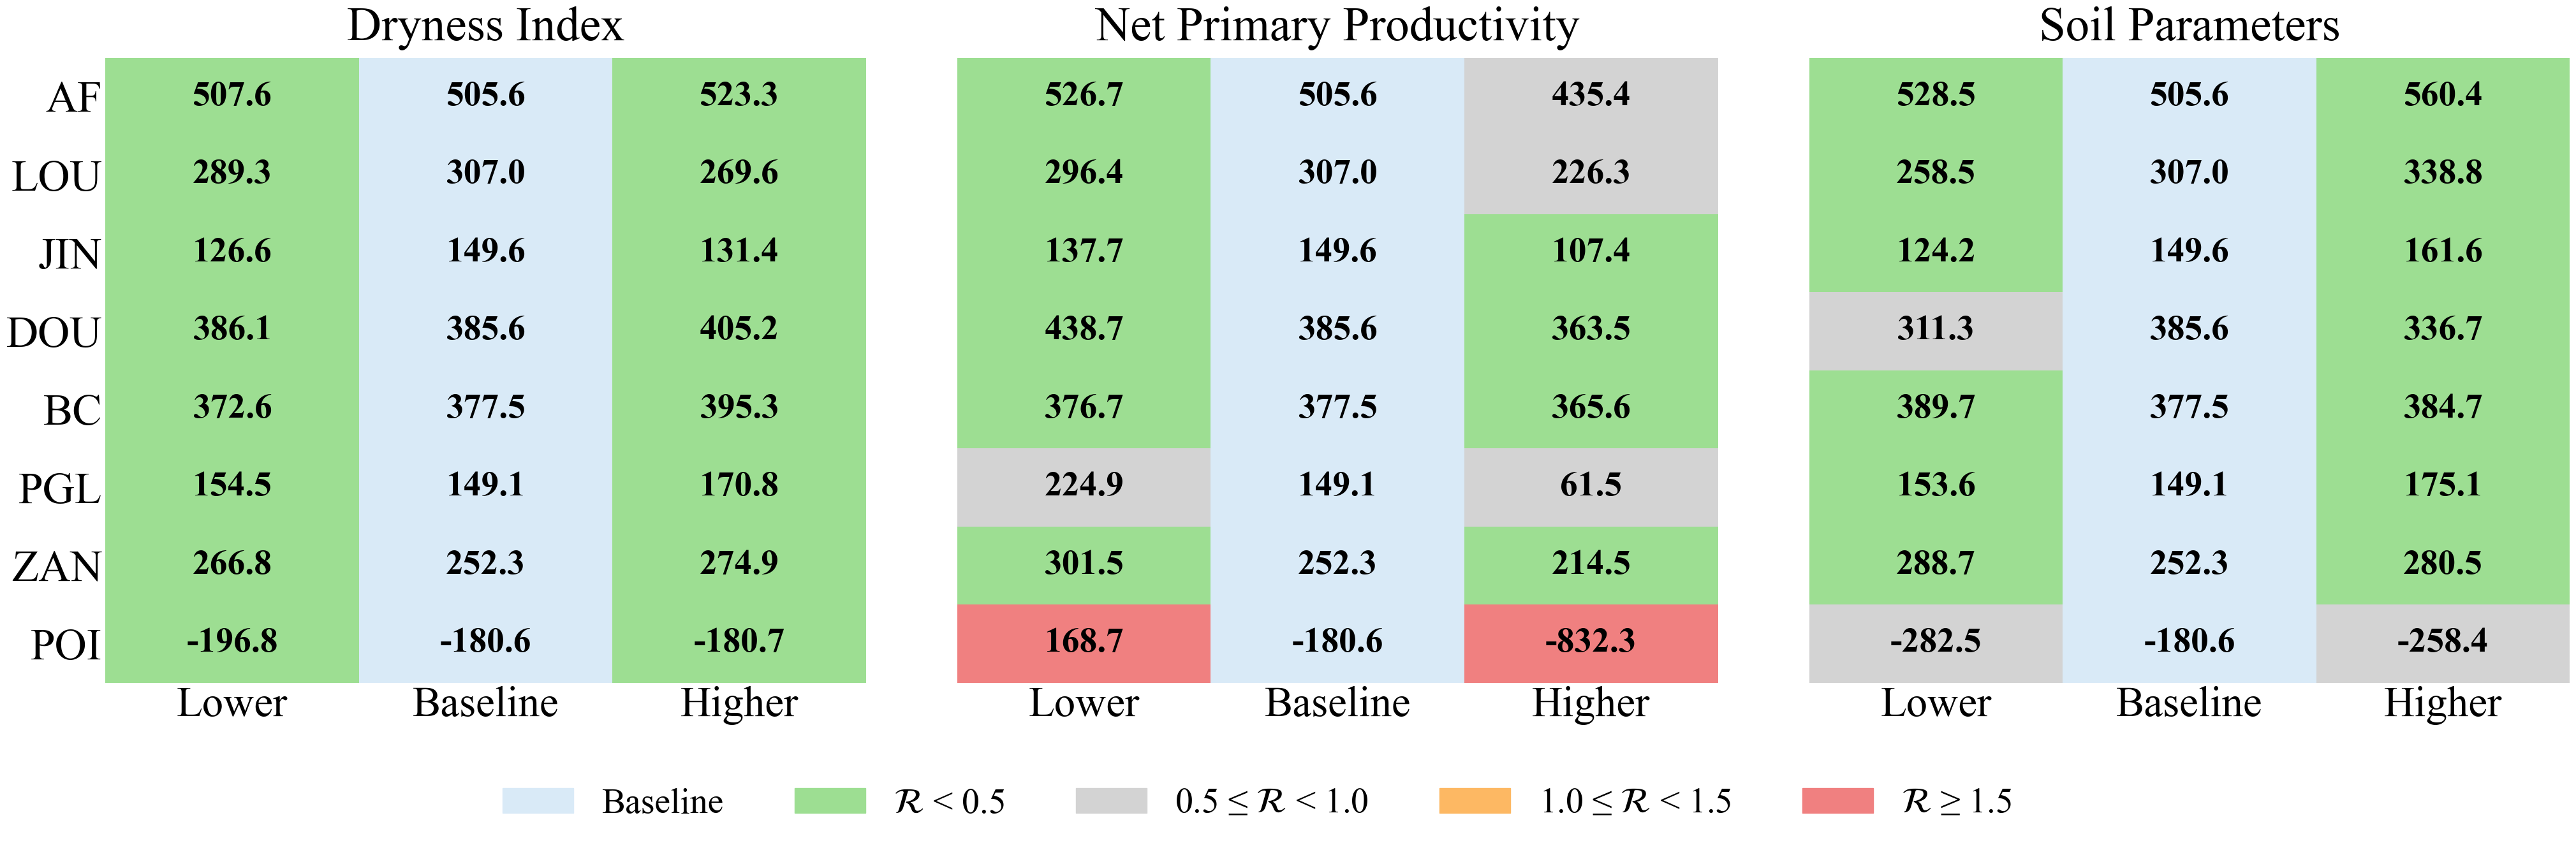

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =============================================================================
# 1. CONFIGURATION
# =============================================================================
FOLDER_PATH = r"C:\Users\rishabh.singh\OneDrive - Texas A&M AgriLife\Desktop\Final Testing (Revision)\Results"

STUDY_ORDER = ['AF', 'LOU', 'JIN', 'DOU', 'BC', 'PGL', 'ZAN', 'POI']
POOLS = ['A', 'P', 'DOC', 'M', 'B']
SCENARIOS = ['Lower', 'Baseline', 'Higher']
CONDITIONS = {'TI': 'Dryness Index', 'NPP': 'Net Primary Productivity', 'Soil': 'Soil Parameters'}

RATIO_THRESHOLDS = [0.5, 1.0, 1.5]
RATIO_COLORS = ['#9DDE92', 'lightgrey', '#FDB863', 'lightcoral']
BASELINE_COLOR = '#D9EAF7'

CT_START, CT_END = 520, 570
NT_START = 600

# =============================================================================
# 2. FILE SELECTION
# =============================================================================
SUFFIXES = ['_Test_Zr', '_Lower', '_Higher', '_Soil_Lower', '_Soil_Higher', '_TI_Lower', '_TI_Higher']
ALLOWED_FILES = [f'{study}{suffix}.csv' for study in STUDY_ORDER for suffix in SUFFIXES]

missing_files = [f for f in ALLOWED_FILES if not os.path.isfile(os.path.join(FOLDER_PATH, f))]

if missing_files:
    raise FileNotFoundError("Missing CSV files:\n" + "\n".join(missing_files))

print(f"All {len(ALLOWED_FILES)} required CSV files found.")

# =============================================================================
# 3. OBSERVATIONS
# =============================================================================
obs = pd.read_excel(os.path.join(FOLDER_PATH, 'gcb15001-sup-0001-tables1.xlsx'), sheet_name='SOC')
obs.columns = obs.columns.str.strip()
obs['Study'] = obs['Study'].str.strip().str.upper()
obs = obs.set_index('Study')

DURATIONS = obs['Study Duration'].to_dict()
OBS_DELTA = obs['Observed Delta SOC'].to_dict()

# =============================================================================
# 4. CALCULATE DELTA SOC
# =============================================================================
def calculate_delta_soc(path, study):
    if study not in DURATIONS or pd.isna(DURATIONS[study]):
        return np.nan

    filename = os.path.basename(path)

    ct_start, ct_end, nt_start = CT_START, CT_END, NT_START

    if study == 'PGL' and filename == 'PGL_Lower.csv':
        ct_start, ct_end, nt_start = 820, 870, 900
        
    elif study == 'POI' and filename == 'POI_Higher.csv':
        ct_start, ct_end, nt_start = 1720, 1770, 1800
        
    elif study == 'PGL' and filename == 'PGL_Soil_Lower.csv':
        ct_start, ct_end, nt_start = 1720, 1770, 1800
        
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip().str.upper()

    years = pd.to_numeric(df['YEARS'], errors='coerce')
    soc = df[POOLS].sum(axis=1)

    ct = soc[years.between(ct_start, ct_end)].mean()
    nt_year = nt_start + DURATIONS[study]

    valid = years.notna() & soc.notna()
    x, y = years[valid].to_numpy(), soc[valid].to_numpy()

    order = np.argsort(x)
    x, y = x[order], y[order]

    if len(x) == 0 or not x[0] <= nt_year <= x[-1]:
        print(f"Missing NT year {nt_year} in {filename}")
        return np.nan

    nt = np.interp(nt_year, x, y)
    return nt - ct

# =============================================================================
# 5. BASELINE DELTA SOC AND MAE
# =============================================================================
baseline = {}

for study in STUDY_ORDER:
    path = os.path.join(FOLDER_PATH, f'{study}_Test_Zr.csv')
    baseline[study] = calculate_delta_soc(path, study)

mae = np.nanmean([abs(baseline[s] - OBS_DELTA[s]) for s in STUDY_ORDER])

print(f"\nBaseline MAE = {mae:.2f} g C/m²")
print(pd.DataFrame({'Observed': OBS_DELTA, 'Baseline': baseline}).reindex(STUDY_ORDER).round(2))

# =============================================================================
# 6. SENSITIVITY CALCULATIONS
# =============================================================================
delta_tables, ratio_tables = {}, {}

for condition in CONDITIONS:
    delta = pd.DataFrame(index=STUDY_ORDER, columns=SCENARIOS, dtype=float)
    ratio = delta.copy()

    for study in STUDY_ORDER:
        delta.loc[study, 'Baseline'] = baseline[study]
        ratio.loc[study, 'Baseline'] = 0 if pd.notna(baseline[study]) else np.nan

        for scenario in ['Lower', 'Higher']:
            suffix = {'TI': f'_TI_{scenario}', 'NPP': f'_{scenario}', 'Soil': f'_Soil_{scenario}'}[condition]
            path = os.path.join(FOLDER_PATH, f'{study}{suffix}.csv')

            value = calculate_delta_soc(path, study)
            delta.loc[study, scenario] = value

            if pd.notna(value) and pd.notna(baseline[study]) and mae > 0:
                ratio.loc[study, scenario] = abs(value - baseline[study]) / mae

    delta_tables[condition] = delta
    ratio_tables[condition] = ratio

# =============================================================================
# 7. SUMMARY TABLE
# =============================================================================
summary = pd.DataFrame({'Observed': OBS_DELTA, 'Baseline': baseline}).reindex(STUDY_ORDER)

for condition in CONDITIONS:
    for scenario in ['Lower', 'Higher']:
        summary[f'{condition}_{scenario}'] = delta_tables[condition][scenario]

print("\nDelta SOC Summary (g C/m²)")
print(summary.round(2).to_string())


# =============================================================================
# PLOT ΔSOC — NPP HIGHER AND LOWER
# =============================================================================
plt.rcParams['font.family'] = 'Times New Roman'

site_order = ['POI', 'ZAN', 'PGL', 'BC', 'DOU', 'JIN', 'LOU', 'AF']

npp = delta_tables['NPP'].reindex(site_order)

colors = {'Higher': '#2677A8', 'Lower': '#D97736'}

for scenario in ['Higher', 'Lower']:

    fig, ax = plt.subplots(figsize=(14, 8))

    values = npp[scenario]

    ax.bar(site_order, values, width=0.65, color=colors[scenario], edgecolor='black', linewidth=1.5)

    ax.axhline(0, color='black', linewidth=1.2)

    ax.set_xlabel('Study Sites', fontsize=26)
    ax.set_ylabel(r'$\Delta$SOC (g C m$^{-2}$)', fontsize=26)
    ax.set_title(f'NPP_{scenario}', fontsize=28, pad=15)

    ax.tick_params(axis='both', labelsize=24, length=6)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.show()
    
# =============================================================================
# 8. FONT CONFIGURATION
# =============================================================================
plt.rcParams['font.family'] = 'Times New Roman'

VALUE_SIZE = 40       # Numbers inside heatmap cells
STUDY_SIZE = 50       # Study names (AF, LOU, JIN, etc.)
SCENARIO_SIZE = 48    # Lower, Baseline, Higher
TITLE_SIZE = 54       # Subplot titles
LEGEND_SIZE = 40      # Legend text

# =============================================================================
# 9. HEATMAP
# =============================================================================
def ratio_color(value, scenario):
    if pd.isna(value):
        return 'white'
    if scenario == 'Baseline':
        return BASELINE_COLOR
    return RATIO_COLORS[np.searchsorted(RATIO_THRESHOLDS, value, side='right')]

def plot_heatmap(ax, delta, ratio, title, show_studies=False):
    for i, study in enumerate(STUDY_ORDER):
        for j, scenario in enumerate(SCENARIOS):
            value = delta.loc[study, scenario]
            r = ratio.loc[study, scenario]

            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       color=ratio_color(r, scenario), linewidth=0))

            if pd.notna(value):
                ax.text(j, i, f'{value:.1f}', ha='center', va='center',
                        fontsize=VALUE_SIZE, fontweight='bold', color='black')

    ax.set_xlim(-0.5, len(SCENARIOS) - 0.5)
    ax.set_ylim(len(STUDY_ORDER) - 0.5, -0.5)

    ax.set_xticks(range(len(SCENARIOS)))
    ax.set_xticklabels(SCENARIOS, fontsize=SCENARIO_SIZE)

    ax.set_yticks(range(len(STUDY_ORDER)))
    ax.set_yticklabels(STUDY_ORDER if show_studies else [''] * len(STUDY_ORDER),
                       fontsize=STUDY_SIZE)

    ax.set_title(title, fontsize=TITLE_SIZE, pad=20)
    ax.tick_params(axis='both', length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

# =============================================================================
# 10. PLOT FIGURE
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(42, 14))

for i, condition in enumerate(CONDITIONS):
    plot_heatmap(axes[i], delta_tables[condition], ratio_tables[condition],
                 CONDITIONS[condition], show_studies=(i == 0))

# =============================================================================
# 11. LEGEND
# =============================================================================
bounds = [-np.inf] + RATIO_THRESHOLDS + [np.inf]
labels = []

for i in range(len(RATIO_COLORS)):
    if i == 0:
        label = rf'$\mathcal{{R}}$ < {bounds[i+1]}'
    elif i == len(RATIO_COLORS) - 1:
        label = rf'$\mathcal{{R}}$ ≥ {bounds[i]}'
    else:
        label = rf'{bounds[i]} ≤ $\mathcal{{R}}$ < {bounds[i+1]}'
    labels.append(label)

patches = [plt.Rectangle((0, 0), 1, 1, color=BASELINE_COLOR, label='Baseline')]
patches += [plt.Rectangle((0, 0), 1, 1, color=c, label=l)
            for c, l in zip(RATIO_COLORS, labels)]

fig.legend(handles=patches, loc='lower center', ncol=5,
           fontsize=LEGEND_SIZE, frameon=False, bbox_to_anchor=(0.5, -0.01))

plt.subplots_adjust(left=0.07, right=0.99, top=0.88, bottom=0.18, wspace=0.12)
plt.show()

All 56 required CSV files found.

Baseline MAE = 137.92 g C/m²
     Observed  Baseline
AF        470    548.73
LOU       200    289.55
JIN       190    157.95
DOU       690    372.19
BC        260    392.25
PGL       430    160.65
ZAN       440    258.05
POI      -161   -159.34

Delta SOC Summary (g C/m²)
     Observed  Baseline  TI_Lower  TI_Higher  NPP_Lower  NPP_Higher  Soil_Lower  Soil_Higher
AF        470    548.73    507.59     523.35     526.75      435.43      528.47       560.36
LOU       200    289.55    289.33     269.59     296.39      226.32      258.48       338.79
JIN       190    157.95    126.60     131.41     137.71      107.38      124.22       161.58
DOU       690    372.19    386.10     405.23     438.70      363.47      311.28       336.73
BC        260    392.25    372.64     395.33     376.68      365.59      389.65       384.68
PGL       430    160.65    154.52     170.83     224.90       61.50      153.64       175.13
ZAN       440    258.05    266.76     274.

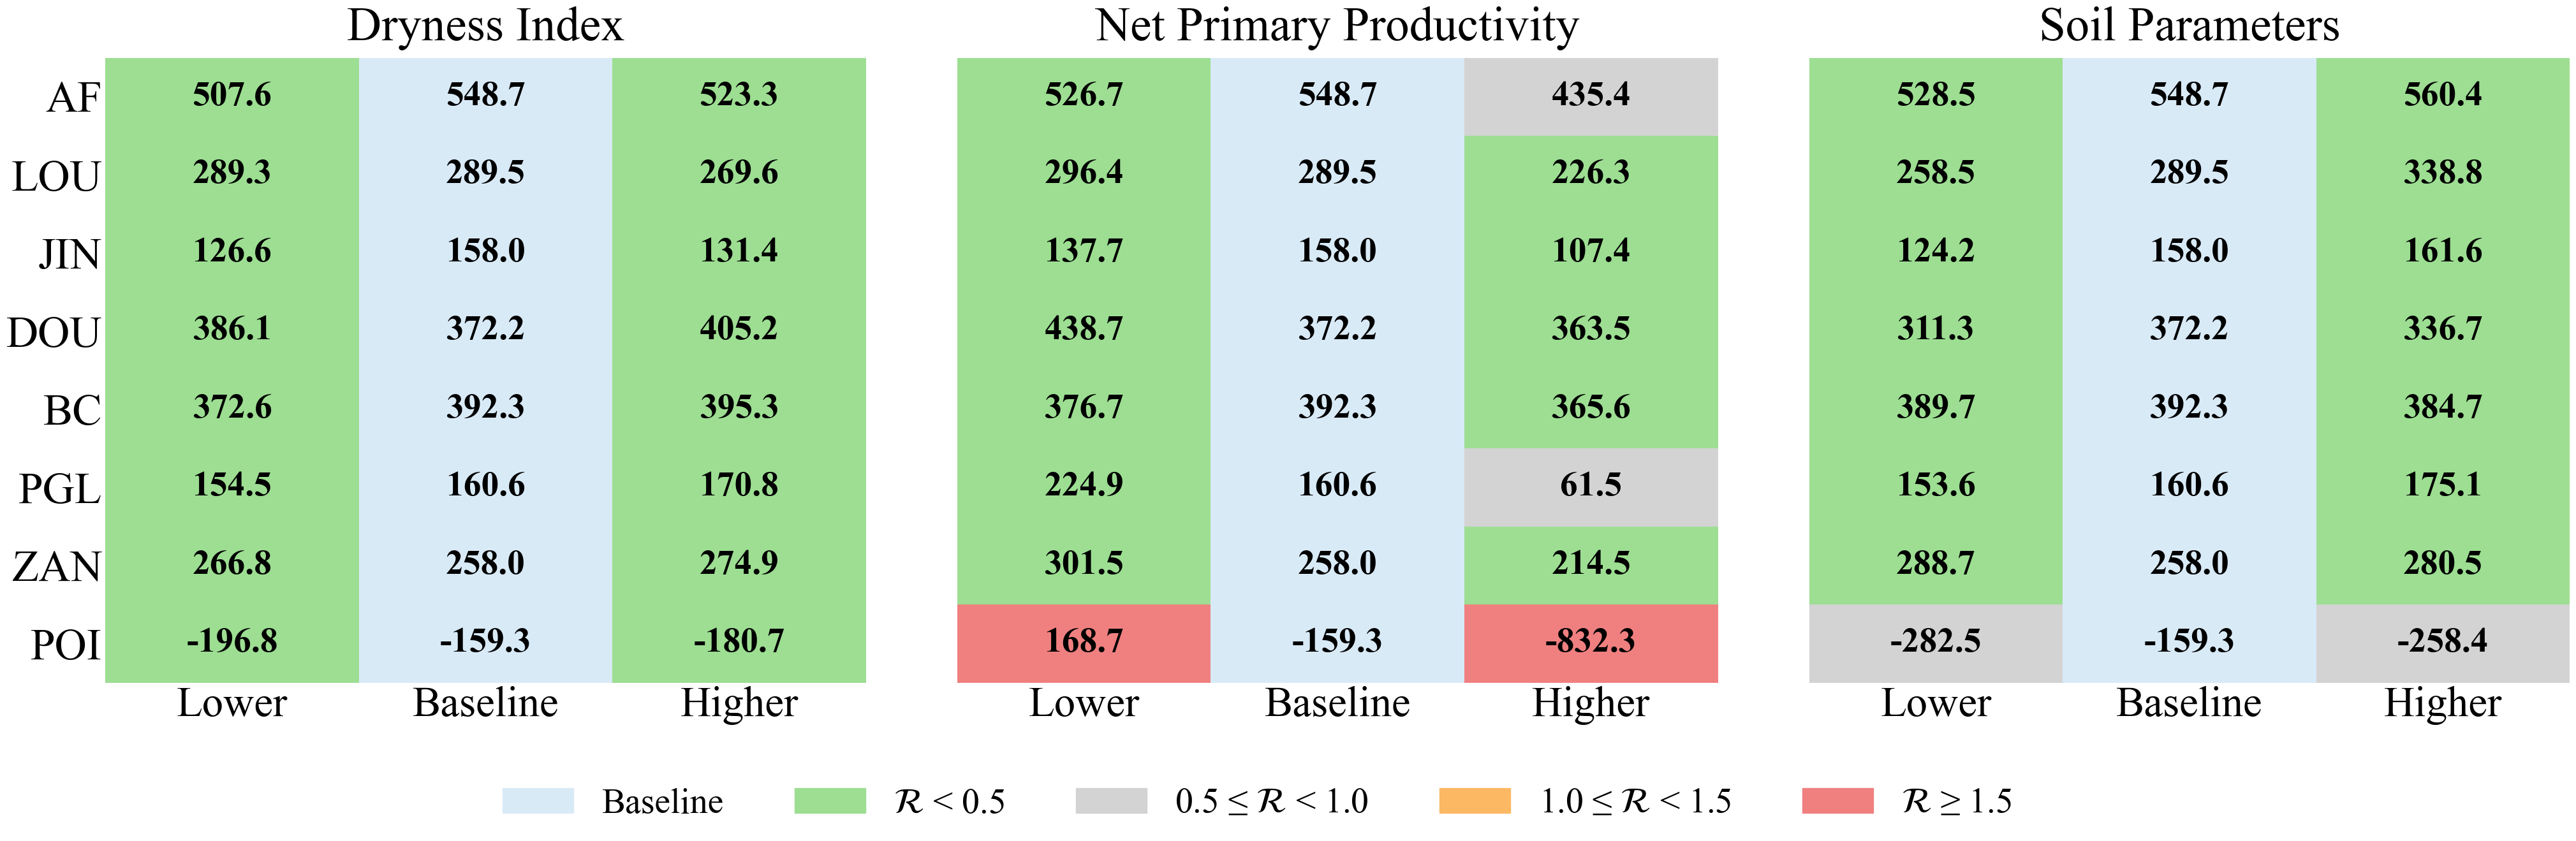

In [2]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =============================================================================
# 1. CONFIGURATION
# =============================================================================
FOLDER_PATH = r"C:\Users\rishabh.singh\OneDrive - Texas A&M AgriLife\Desktop\Final Testing (Revision)\Results"

STUDY_ORDER = ['AF', 'LOU', 'JIN', 'DOU', 'BC', 'PGL', 'ZAN', 'POI']
POOLS = ['A', 'P', 'DOC', 'M', 'B']
SCENARIOS = ['Lower', 'Baseline', 'Higher']
CONDITIONS = {'TI': 'Dryness Index', 'NPP': 'Net Primary Productivity', 'Soil': 'Soil Parameters'}

RATIO_THRESHOLDS = [0.5, 1.0, 1.5]
RATIO_COLORS = ['#9DDE92', 'lightgrey', '#FDB863', 'lightcoral']
BASELINE_COLOR = '#D9EAF7'

CT_START, CT_END = 520, 570
NT_START = 600

# =============================================================================
# 2. FILE SELECTION
# =============================================================================
SUFFIXES = ['_Test_Zr', '_Lower', '_Higher', '_Soil_Lower', '_Soil_Higher', '_TI_Lower', '_TI_Higher']
ALLOWED_FILES = [f'{study}{suffix}.csv' for study in STUDY_ORDER for suffix in SUFFIXES]

missing_files = [f for f in ALLOWED_FILES if not os.path.isfile(os.path.join(FOLDER_PATH, f))]

if missing_files:
    raise FileNotFoundError("Missing CSV files:\n" + "\n".join(missing_files))

print(f"All {len(ALLOWED_FILES)} required CSV files found.")

# =============================================================================
# 3. OBSERVATIONS
# =============================================================================
obs = pd.read_excel(os.path.join(FOLDER_PATH, 'gcb15001-sup-0001-tables1.xlsx'), sheet_name='SOC')
obs.columns = obs.columns.str.strip()
obs['Study'] = obs['Study'].str.strip().str.upper()
obs = obs.set_index('Study')

DURATIONS = obs['Study Duration'].to_dict()
OBS_DELTA = obs['Observed Delta SOC'].to_dict()

# =============================================================================
# 4. CALCULATE DELTA SOC
# =============================================================================
def calculate_delta_soc(path, study):
    if study not in DURATIONS or pd.isna(DURATIONS[study]):
        return np.nan

    filename = os.path.basename(path)

    ct_start, ct_end, nt_start = CT_START, CT_END, NT_START

    if study == 'PGL' and filename == 'PGL_Lower.csv':
        ct_start, ct_end, nt_start = 820, 870, 900

    elif study == 'POI' and filename == 'POI_Higher.csv':
        ct_start, ct_end, nt_start = 1720, 1770, 1800

    elif study == 'PGL' and filename == 'PGL_Soil_Lower.csv':
        ct_start, ct_end, nt_start = 1720, 1770, 1800

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip().str.upper()

    years = pd.to_numeric(df['YEARS'], errors='coerce')
    soc = df[POOLS].sum(axis=1)

    ct = soc[years.between(ct_start, ct_end)].mean()
    nt_year = nt_start + DURATIONS[study]

    valid = years.notna() & soc.notna()
    x, y = years[valid].to_numpy(), soc[valid].to_numpy()

    order = np.argsort(x)
    x, y = x[order], y[order]

    if len(x) == 0 or not x[0] <= nt_year <= x[-1]:
        print(f"Missing NT year {nt_year} in {filename}")
        return np.nan

    nt = np.interp(nt_year, x, y)
    return nt - ct

# =============================================================================
# 5. BASELINE DELTA SOC AND MAE
# =============================================================================
baseline = {}

for study in STUDY_ORDER:
    path = os.path.join(FOLDER_PATH, f'{study}_Test_Zr.csv')
    baseline[study] = calculate_delta_soc(path, study)

mae = np.nanmean([abs(baseline[s] - OBS_DELTA[s]) for s in STUDY_ORDER])

print(f"\nBaseline MAE = {mae:.2f} g C/m²")
print(pd.DataFrame({'Observed': OBS_DELTA, 'Baseline': baseline}).reindex(STUDY_ORDER).round(2))

# =============================================================================
# 6. SENSITIVITY CALCULATIONS
# =============================================================================
delta_tables, ratio_tables = {}, {}

for condition in CONDITIONS:
    delta = pd.DataFrame(index=STUDY_ORDER, columns=SCENARIOS, dtype=float)
    ratio = delta.copy()

    for study in STUDY_ORDER:
        delta.loc[study, 'Baseline'] = baseline[study]
        ratio.loc[study, 'Baseline'] = 0 if pd.notna(baseline[study]) else np.nan

        for scenario in ['Lower', 'Higher']:
            suffix = {'TI': f'_TI_{scenario}', 'NPP': f'_{scenario}', 'Soil': f'_Soil_{scenario}'}[condition]
            path = os.path.join(FOLDER_PATH, f'{study}{suffix}.csv')

            value = calculate_delta_soc(path, study)
            delta.loc[study, scenario] = value

            if pd.notna(value) and pd.notna(baseline[study]) and mae > 0:
                ratio.loc[study, scenario] = abs(value - baseline[study]) / mae

    delta_tables[condition] = delta
    ratio_tables[condition] = ratio

# =============================================================================
# 7. SUMMARY TABLE
# =============================================================================
summary = pd.DataFrame({'Observed': OBS_DELTA, 'Baseline': baseline}).reindex(STUDY_ORDER)

for condition in CONDITIONS:
    for scenario in ['Lower', 'Higher']:
        summary[f'{condition}_{scenario}'] = delta_tables[condition][scenario]

print("\nDelta SOC Summary (g C/m²)")
print(summary.round(2).to_string())

# =============================================================================
# 8. FONT CONFIGURATION
# =============================================================================
plt.rcParams['font.family'] = 'Times New Roman'

VALUE_SIZE = 40
STUDY_SIZE = 50
SCENARIO_SIZE = 48
TITLE_SIZE = 54
LEGEND_SIZE = 40

# =============================================================================
# 9. HEATMAP
# =============================================================================
def ratio_color(value, scenario):
    if pd.isna(value):
        return 'white'
    if scenario == 'Baseline':
        return BASELINE_COLOR
    return RATIO_COLORS[np.searchsorted(RATIO_THRESHOLDS, value, side='right')]

def plot_heatmap(ax, delta, ratio, title, show_studies=False):
    for i, study in enumerate(STUDY_ORDER):
        for j, scenario in enumerate(SCENARIOS):
            value = delta.loc[study, scenario]
            r = ratio.loc[study, scenario]

            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1,
                                       color=ratio_color(r, scenario), linewidth=0))

            if pd.notna(value):
                ax.text(j, i, f'{value:.1f}', ha='center', va='center',
                        fontsize=VALUE_SIZE, fontweight='bold', color='black')

    ax.set_xlim(-0.5, len(SCENARIOS) - 0.5)
    ax.set_ylim(len(STUDY_ORDER) - 0.5, -0.5)

    ax.set_xticks(range(len(SCENARIOS)))
    ax.set_xticklabels(SCENARIOS, fontsize=SCENARIO_SIZE)

    ax.set_yticks(range(len(STUDY_ORDER)))
    ax.set_yticklabels(STUDY_ORDER if show_studies else [''] * len(STUDY_ORDER),
                       fontsize=STUDY_SIZE)

    ax.set_title(title, fontsize=TITLE_SIZE, pad=20)
    ax.tick_params(axis='both', length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

# =============================================================================
# 10. PLOT FIGURE
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(42, 14))

for i, condition in enumerate(CONDITIONS):
    plot_heatmap(axes[i], delta_tables[condition], ratio_tables[condition],
                 CONDITIONS[condition], show_studies=(i == 0))

# =============================================================================
# 11. LEGEND
# =============================================================================
bounds = [-np.inf] + RATIO_THRESHOLDS + [np.inf]
labels = []

for i in range(len(RATIO_COLORS)):
    if i == 0:
        label = rf'$\mathcal{{R}}$ < {bounds[i+1]}'
    elif i == len(RATIO_COLORS) - 1:
        label = rf'$\mathcal{{R}}$ ≥ {bounds[i]}'
    else:
        label = rf'{bounds[i]} ≤ $\mathcal{{R}}$ < {bounds[i+1]}'
    labels.append(label)

patches = [plt.Rectangle((0, 0), 1, 1, color=BASELINE_COLOR, label='Baseline')]
patches += [plt.Rectangle((0, 0), 1, 1, color=c, label=l)
            for c, l in zip(RATIO_COLORS, labels)]

fig.legend(handles=patches, loc='lower center', ncol=5,
           fontsize=LEGEND_SIZE, frameon=False, bbox_to_anchor=(0.5, -0.01))

plt.subplots_adjust(left=0.07, right=0.99, top=0.88, bottom=0.18, wspace=0.12)
plt.show()